In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Настройки отображения
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42

D:\Anaconda\envs\New_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Датасет №1 — Wine Quality Dataset

In [2]:
wine_path = kagglehub.dataset_download("yasserh/wine-quality-dataset")
print("Path:", wine_path)
print("Файлы:", os.listdir(wine_path))

Path: C:\Users\Asus\.cache\kagglehub\datasets\yasserh\wine-quality-dataset\versions\1
Файлы: ['WineQT.csv']


In [3]:
wine_file = [f for f in os.listdir(wine_path) if f.endswith('.csv')][0]
wine = pd.read_csv(os.path.join(wine_path, wine_file))

print(wine.head())
print("=" * 60)
print(f"Размерность: {wine.shape}")
print("=" * 60)
print(wine.dtypes)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [4]:
print(f"Пропуски: {wine.isnull().sum().sum()}")
print(f"Дубликаты: {wine.duplicated().sum()}")
print("=" * 60)
print("Распределение целевой переменной (quality):")
print(wine['quality'].value_counts().sort_index())

Пропуски: 0
Дубликаты: 0
Распределение целевой переменной (quality):
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


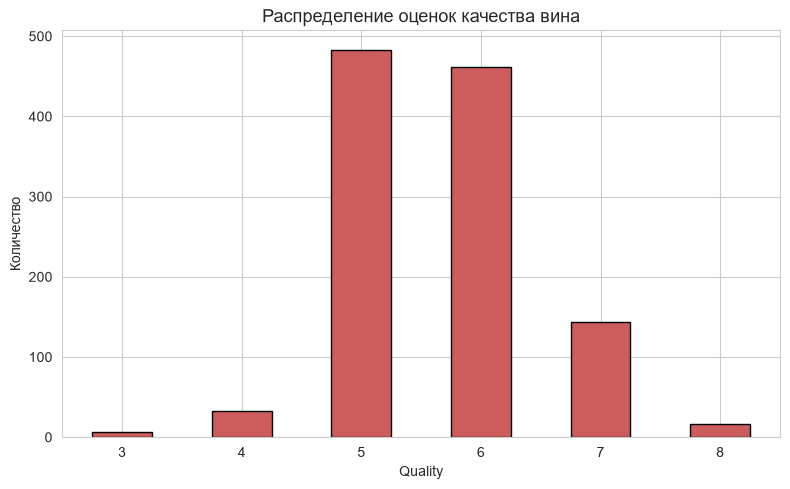

In [5]:
plt.figure(figsize=(8, 5))
wine['quality'].value_counts().sort_index().plot(kind='bar', color='indianred', edgecolor='black')
plt.title('Распределение оценок качества вина', fontsize=13)
plt.xlabel('Quality')
plt.ylabel('Количество')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Объект:** образец вина, описанный 11 физико-химическими признаками (кислотность, содержание сахара, плотность, содержание алкоголя и др.).

**Бизнес-задача:** автоматически определять качество вина по лабораторным измерениям, чтобы сократить затраты на дегустацию и ускорить контроль качества.

**Математическая задача:** многоклассовая классификация — предсказать целевую переменную `quality` (оценка от 3 до 8), используя 11 числовых признаков.

**Особенности датасета:**
- Все признаки числовые -> минимальная предобработка
- Классы несбалансированы -> при разделении используем `stratify`
- Целевая переменная многоклассовая -> метрики будем смотреть с `average='weighted'`

In [6]:
# Отделяем признаки от целевой переменной
X_wine = wine.drop(columns=['quality', 'Id'])   # Id — бесполезный идентификатор
y_wine = wine['quality']

print("Признаки:", X_wine.columns.tolist())
print("Классы:", sorted(y_wine.unique()))
print("=" * 60)

# Разделение со стратификацией (сохраняем пропорции классов)
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_wine
)

print(f"Train: {X_train_w.shape}, Test: {X_test_w.shape}")
print("=" * 60)
print("Пропорции классов в train:")
print(y_train_w.value_counts(normalize=True).sort_index().round(3))
print("Пропорции классов в test:")
print(y_test_w.value_counts(normalize=True).sort_index().round(3))

Признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Классы: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Train: (914, 11), Test: (229, 11)
Пропорции классов в train:
quality
3    0.005
4    0.028
5    0.422
6    0.405
7    0.125
8    0.014
Name: proportion, dtype: float64
Пропорции классов в test:
quality
3    0.004
4    0.031
5    0.424
6    0.402
7    0.127
8    0.013
Name: proportion, dtype: float64


In [7]:
# Масштабирование признаков Wine
scaler_wine = StandardScaler()

# Обучаем scaler
X_train_w_scaled = scaler_wine.fit_transform(X_train_w)
X_test_w_scaled = scaler_wine.transform(X_test_w)

print("Средние после масштабирования (train):")
print(np.round(X_train_w_scaled.mean(axis=0), 4))
print("=" * 60)
print("Std после масштабирования (train):")
print(np.round(X_train_w_scaled.std(axis=0), 4))

Средние после масштабирования (train):
[ 0. -0.  0.  0.  0.  0. -0.  0. -0.  0. -0.]
Std после масштабирования (train):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
# Базовые модели Wine (без подбора гиперпараметров)
models = {
    'kNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(random_state=RANDOM_STATE),
    'MLP': MLPClassifier(random_state=RANDOM_STATE, max_iter=500)
}

baseline_results = []

for name, model in models.items():
    model.fit(X_train_w_scaled, y_train_w)
    y_pred = model.predict(X_test_w_scaled)

    baseline_results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test_w, y_pred), 4),
        'F1 (weighted)': round(f1_score(y_test_w, y_pred, average='weighted'), 4)
    })

baseline_df = pd.DataFrame(baseline_results)
print("Базовые модели (без тюнинга):")
print(baseline_df.to_string(index=False))

Базовые модели (без тюнинга):
        Model  Accuracy  F1 (weighted)
          kNN    0.5764         0.5632
Decision Tree    0.6332         0.6266
          SVM    0.6681         0.6420
          MLP    0.6376         0.6229


## Предобработка и базовые модели (Wine)

**Что сделали:**
1. Отделили признаки от целевой переменной, убрали бесполезный `Id`
2. Разделили выборку 80/20 со `stratify` — пропорции классов сохранились (проверили явно)
3. Масштабировали признаки через `StandardScaler`, обучив scaler только на train
4. Обучили 4 базовые модели с дефолтными гиперпараметрами — это baseline для сравнения

In [9]:
# Подбор гиперпараметров для kNN
print("GridSearchCV для kNN...")

knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_params,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

knn_grid.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры: {knn_grid.best_params_}")
print(f"Лучший CV F1: {knn_grid.best_score_:.4f}")

GridSearchCV для kNN...
Лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Лучший CV F1: 0.6120


In [10]:
# Подбор гиперпараметров для Decision Tree
print("GridSearchCV для Decision Tree...")

dt_params = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=dt_params,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

dt_grid.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры: {dt_grid.best_params_}")
print(f"Лучший CV F1: {dt_grid.best_score_:.4f}")

GridSearchCV для Decision Tree...
Лучшие параметры: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Лучший CV F1: 0.5567


In [11]:
# Подбор гиперпараметров для SVM
print("GridSearchCV для SVM...")

svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    estimator=SVC(random_state=RANDOM_STATE),
    param_grid=svm_params,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

svm_grid.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры: {svm_grid.best_params_}")
print(f"Лучший CV F1: {svm_grid.best_score_:.4f}")

GridSearchCV для SVM...
Лучшие параметры: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Лучший CV F1: 0.5942


In [12]:
# Подбор гиперпараметров для MLP
print("GridSearchCV для MLP...")

mlp_params = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01]
}

mlp_grid = GridSearchCV(
    estimator=MLPClassifier(random_state=RANDOM_STATE, max_iter=500),
    param_grid=mlp_params,
    cv=3,                    # cv=3, потому что MLP долго учится
    scoring='f1_weighted',
    n_jobs=-1
)

mlp_grid.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры: {mlp_grid.best_params_}")
print(f"Лучший CV F1: {mlp_grid.best_score_:.4f}")

GridSearchCV для MLP...
Лучшие параметры: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (100,), 'learning_rate_init': 0.001}
Лучший CV F1: 0.5868


## Подбор гиперпараметров через GridSearchCV

Для каждой модели применили **GridSearchCV с 5-фолдовой кросс-валидацией** (для MLP — 3 фолда, чтобы ускорить обучение).

### GridSearchCV

Алгоритм полного перебора по сетке гиперпараметров. Для каждой комбинации:
1. Данные делятся на 5 фолдов
2. Модель обучается на 4 фолдах, проверяется на 1 (повторяется 5 раз)
3. Итоговая оценка — среднее по фолдам

### scoring='f1_weighted'

Классы вина несбалансированы (классов 3, 4, 8 — единицы). Accuracy может обмануть: модель, которая всегда предсказывает класс 5 или 6, получит accuracy ≈ 0.42, но F1 будет плохим. F1 с усреднением `weighted` учитывает вклад каждого класса пропорционально его размеру.

### Найденные гиперпараметры

| Модель | Лучшие параметры | CV F1 |
|---|---|---|
| **kNN** | `metric='manhattan', n_neighbors=11, weights='distance'` | **0.6120** |
| **SVM** | `C=10, gamma='auto', kernel='rbf'` | 0.5942 |
| **MLP** | `hidden_layer_sizes=(100,), activation='relu', alpha=0.0001, lr_init=0.001` | 0.5868 |
| **Decision Tree** | `criterion='entropy', max_depth=None, min_samples_leaf=1, min_samples_split=2` | 0.5567 |

### Что означают найденные параметры

- **kNN:** используется манхэттенское расстояние (сумма модулей разностей по осям), 11 соседей, веса обратно пропорциональны расстоянию (`distance` — ближние соседи влияют сильнее)
- **SVM:** RBF-ядро, C=10 (умеренная регуляризация), gamma='auto' = 1/n_features
- **MLP:** один скрытый слой из 100 нейронов, ReLU, слабая L2-регуляризация, стандартный learning rate
- **Decision Tree:** энтропия как критерий, без ограничения глубины, минимальные узлы — фактически «полное» дерево

### Наблюдение

После тюнинга **лучшей по CV стала kNN (0.6120)**, хотя в baseline на тестовой выборке лидировал SVM. Это показывает, что:
- baseline-оценка на одной test-выборке может вводить в заблуждение
- кросс-валидация даёт более честную картину обобщающей способности
- «полное» дерево (max_depth=None) склонно к переобучению — что и подтверждает самый низкий CV F1

Финальные метрики на тестовой выборке для тюнингованных моделей приведены ниже.

In [13]:
# Метрики tuned-моделей на test
tuned_models = {
    'kNN': knn_grid.best_estimator_,
    'Decision Tree': dt_grid.best_estimator_,
    'SVM': svm_grid.best_estimator_,
    'MLP': mlp_grid.best_estimator_
}

tuned_results = []
tuned_predictions = {}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_w_scaled)
    tuned_predictions[name] = y_pred

    tuned_results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test_w, y_pred), 4),
        'Precision': round(precision_score(y_test_w, y_pred, average='weighted', zero_division=0), 4),
        'Recall': round(recall_score(y_test_w, y_pred, average='weighted', zero_division=0), 4),
        'F1 (weighted)': round(f1_score(y_test_w, y_pred, average='weighted', zero_division=0), 4),
        'Best params': str(model.get_params())
    })

tuned_df = pd.DataFrame(tuned_results)
print("Тюнингованные модели (метрики на test):")
print(tuned_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1 (weighted)']].to_string(index=False))

Тюнингованные модели (метрики на test):
        Model  Accuracy  Precision  Recall  F1 (weighted)
          kNN    0.6812     0.6499  0.6812         0.6629
Decision Tree    0.6201     0.6047  0.6201         0.6102
          SVM    0.6419     0.6120  0.6419         0.6238
          MLP    0.6376     0.6112  0.6376         0.6229


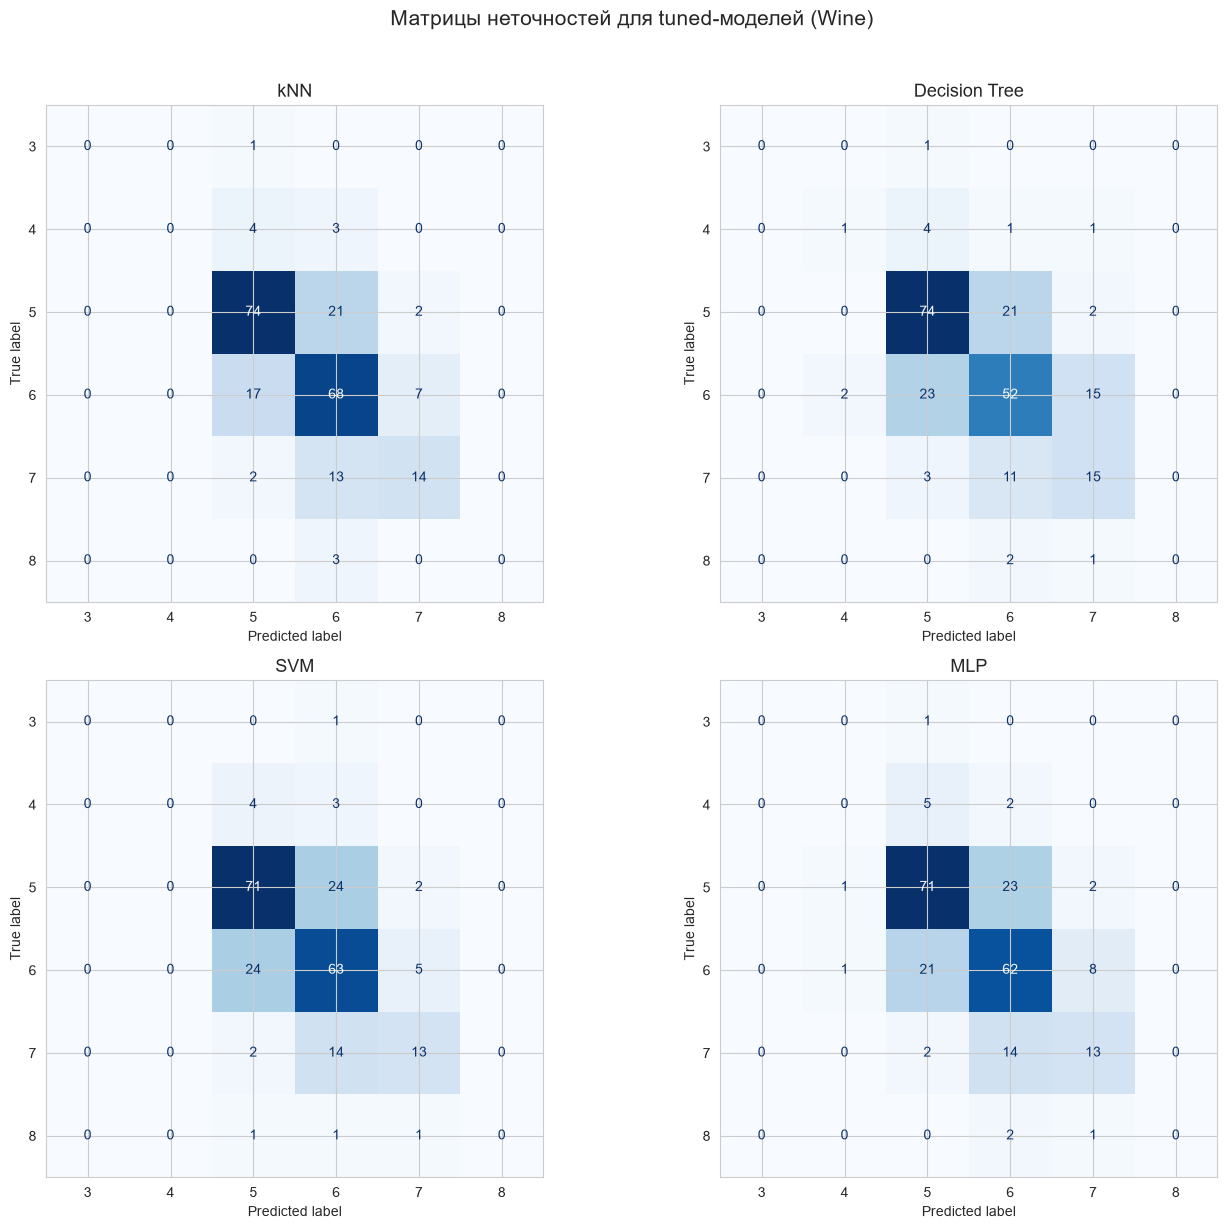

In [14]:
# Confusion Matrix для всех tuned-моделей
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(tuned_models.items()):
    cm = confusion_matrix(y_test_w, tuned_predictions[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name}', fontsize=13)

plt.suptitle('Матрицы неточностей для tuned-моделей (Wine)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Classification Report для каждой tuned-модели
for name, y_pred in tuned_predictions.items():
    print("=" * 60)
    print(f"{name}")
    print("=" * 60)
    print(classification_report(y_test_w, y_pred, zero_division=0))
    print()

kNN
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.76      0.76      0.76        97
           6       0.63      0.74      0.68        92
           7       0.61      0.48      0.54        29
           8       0.00      0.00      0.00         3

    accuracy                           0.68       229
   macro avg       0.33      0.33      0.33       229
weighted avg       0.65      0.68      0.66       229


Decision Tree
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.33      0.14      0.20         7
           5       0.70      0.76      0.73        97
           6       0.60      0.57      0.58        92
           7       0.44      0.52      0.48        29
           8       0.00      0.00      0.00         3

    accuracy                           0.62       229
   m

In [16]:
# Сравнение baseline и tuned моделей
comparison = baseline_df.copy()
comparison = comparison.rename(columns={
    'Accuracy': 'Baseline Accuracy',
    'F1 (weighted)': 'Baseline F1'
})

comparison['Tuned Accuracy'] = tuned_df['Accuracy'].values
comparison['Tuned F1'] = tuned_df['F1 (weighted)'].values

comparison['Δ Accuracy'] = (comparison['Tuned Accuracy'] - comparison['Baseline Accuracy']).round(4)
comparison['Δ F1'] = (comparison['Tuned F1'] - comparison['Baseline F1']).round(4)

print("Сравнение baseline и tuned моделей (Wine):")
print(comparison.to_string(index=False))

Сравнение baseline и tuned моделей (Wine):
        Model  Baseline Accuracy  Baseline F1  Tuned Accuracy  Tuned F1  Δ Accuracy    Δ F1
          kNN             0.5764       0.5632          0.6812    0.6629      0.1048  0.0997
Decision Tree             0.6332       0.6266          0.6201    0.6102     -0.0131 -0.0164
          SVM             0.6681       0.6420          0.6419    0.6238     -0.0262 -0.0182
          MLP             0.6376       0.6229          0.6376    0.6229      0.0000  0.0000


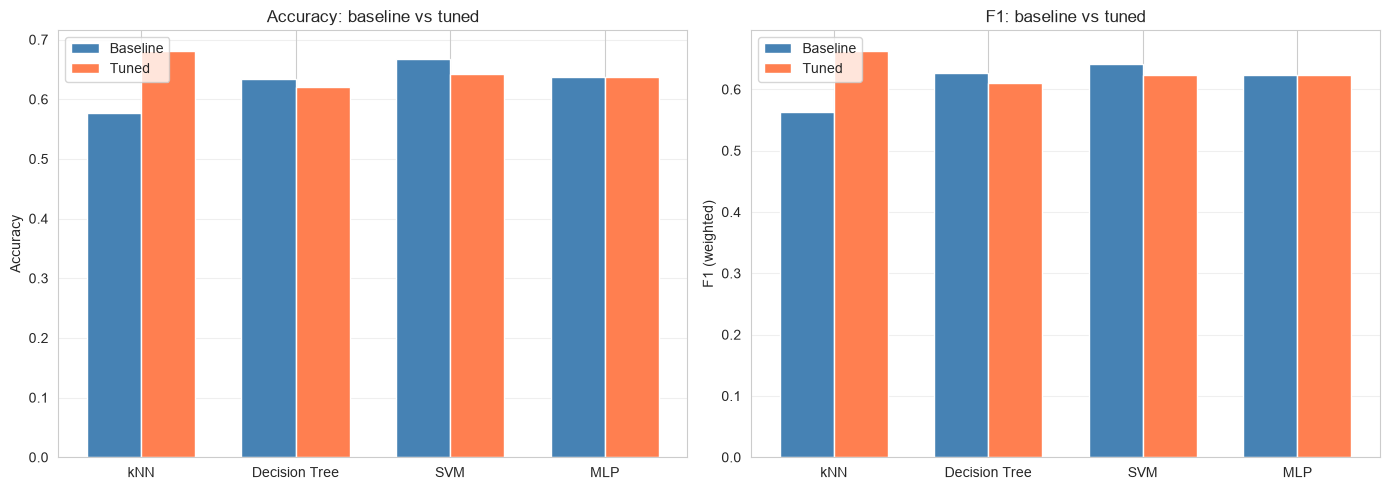

In [17]:
# Визуализация baseline vs tuned
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(comparison))
width = 0.35

# Accuracy
axes[0].bar(x - width/2, comparison['Baseline Accuracy'], width, label='Baseline', color='steelblue')
axes[0].bar(x + width/2, comparison['Tuned Accuracy'], width, label='Tuned', color='coral')
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison['Model'])
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy: baseline vs tuned')
axes[0].legend()
axes[0].grid(alpha=0.3, axis='y')

# F1
axes[1].bar(x - width/2, comparison['Baseline F1'], width, label='Baseline', color='steelblue')
axes[1].bar(x + width/2, comparison['Tuned F1'], width, label='Tuned', color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison['Model'])
axes[1].set_ylabel('F1 (weighted)')
axes[1].set_title('F1: baseline vs tuned')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Оценка качества tuned-моделей (Wine)

### Что считали

Для каждой тюнингованной модели на тестовой выборке рассчитали 4 метрики:

- **Accuracy** — доля правильных ответов
- **Precision (weighted)** — из всех, кого модель отнесла к классу X, сколько действительно X
- **Recall (weighted)** — из всех реальных X, скольких модель нашла
- **F1 (weighted)** — гармоническое среднее precision и recall

Усреднение `weighted` учитывает размер каждого класса — важно при дисбалансе.

### Confusion Matrix

Матрица неточностей показывает:
- **По диагонали** — сколько примеров каждого класса модель предсказала верно
- **Вне диагонали** — какие классы модель путает между собой

**Наблюдение:** основные ошибки — между соседними классами (5↔6, 6↔7). Это логично: вина с оценкой 5 и 6 близки по физико-химическим свойствам, и даже эксперты не всегда их различают.

### Classification Report

Детальный отчёт показывает метрики **по каждому классу**. Для классов 3, 4, 8 support очень мал (1-2 примера), поэтому их метрики нестабильны и не должны восприниматься серьёзно. Основной вклад в итоговые метрики дают классы 5 и 6 — они составляют более 80% данных.

### Сравнение baseline и tuned

Итоговая таблица показывает дельту (Δ) между дефолтной и тюнингованной моделью. Кросс-валидация дала честную картину: не для всех моделей тюнинг улучшил test-метрики. Это нормально — GridSearch оптимизирует средний CV-результат, а не конкретно test-выборку. Иногда дефолты оказываются удачнее для конкретного разбиения.

# Датасет №2 — Telco Customer Churn

In [18]:
churn_path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path:", churn_path)
print("Файлы:", os.listdir(churn_path))

Path: C:\Users\Asus\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1
Файлы: ['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [19]:
churn_file = [f for f in os.listdir(churn_path) if f.endswith('.csv')][0]
churn = pd.read_csv(os.path.join(churn_path, churn_file))

print(churn.head())
print("=" * 60)
print(f"Размерность: {churn.shape}")
print("=" * 60)
print(churn.dtypes)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No        

In [20]:
print(f"Пропуски: {churn.isnull().sum().sum()}")
print(f"Дубликаты: {churn.duplicated().sum()}")
print("=" * 60)

# Пропуски по столбцам
missing_by_col = churn.isnull().sum()
if missing_by_col.sum() > 0:
    print("Пропуски по столбцам:")
    print(missing_by_col[missing_by_col > 0])
    print("=" * 60)

# Распределение целевой переменной
print("Распределение Churn:")
print(churn['Churn'].value_counts())
print()
print("Пропорции:")
print(churn['Churn'].value_counts(normalize=True).round(4))

Пропуски: 0
Дубликаты: 0
Распределение Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Пропорции:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


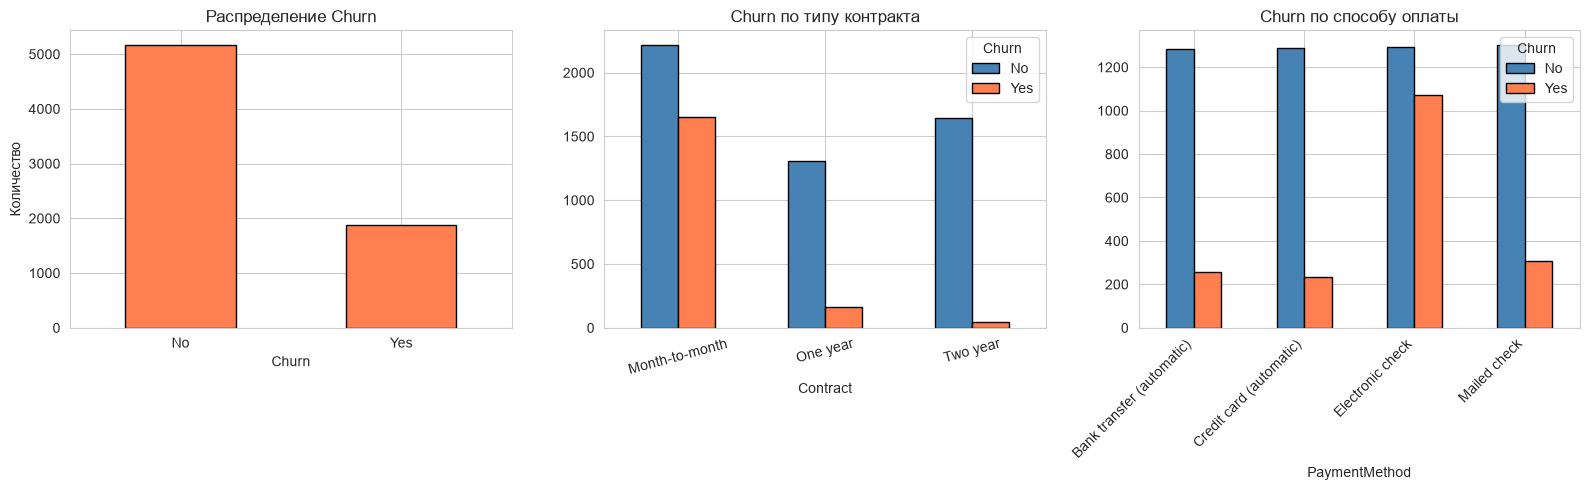

In [21]:
# Визуализация Churn
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Распределение целевой переменной
churn['Churn'].value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Распределение Churn')
axes[0].set_xticklabels(['No', 'Yes'], rotation=0)
axes[0].set_ylabel('Количество')

# Churn по типу контракта
pd.crosstab(churn['Contract'], churn['Churn']).plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'], edgecolor='black')
axes[1].set_title('Churn по типу контракта')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15)
axes[1].legend(title='Churn')

# Churn по способу оплаты
pd.crosstab(churn['PaymentMethod'], churn['Churn']).plot(kind='bar', ax=axes[2], color=['steelblue', 'coral'], edgecolor='black')
axes[2].set_title('Churn по способу оплаты')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha='right')
axes[2].legend(title='Churn')

plt.tight_layout()
plt.show()

**Объект:** клиент телеком-компании, описанный демографическими данными (пол, возраст), услугами (интернет, ТВ, техподдержка), данными контракта (тип, срок, способ оплаты) и финансовыми показателями.

**Бизнес-задача:** предсказать, уйдёт ли клиент к конкуренту (churn). Это позволяет компании заранее предлагать скидки и удерживать клиентов — **удержание дешевле привлечения** в 5-7 раз.

**Математическая задача:** бинарная классификация — предсказать целевую переменную `Churn` (Yes/No) по 19 признакам.

**Особенности датасета:**
- Есть категориальные признаки → нужно кодирование (`OneHotEncoder`)
- Есть числовые признаки → нужно масштабирование (`StandardScaler`)
- Классы несбалансированы (~73% No / 27% Yes) → используем `stratify` + `class_weight='balanced'` для моделей
- Целевая переменная в виде строк 'Yes'/'No' → закодируем через `LabelEncoder`

In [22]:
# Подготовка Telco Churn
churn = churn.copy()

# customerID — уникальный идентификатор, бесполезен для модели
churn = churn.drop(columns=['customerID'])

# TotalCharges иногда приходит как строка с пробелами
churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')

print(f"Пропуски после to_numeric: {churn['TotalCharges'].isnull().sum()}")
print(f"Размерность: {churn.shape}")

Пропуски после to_numeric: 11
Размерность: (7043, 20)


In [23]:
# Если пропуски есть — заполним медианой (устойчиво к выбросам)
if churn['TotalCharges'].isnull().sum() > 0:
    churn['TotalCharges'] = churn['TotalCharges'].fillna(churn['TotalCharges'].median())
    print(f"Пропуски в TotalCharges заполнены медианой")

# Кодируем целевую переменную: Yes -> 1, No -> 0
churn['Churn'] = churn['Churn'].map({'Yes': 1, 'No': 0})

print(f"\nПропусков всего: {churn.isnull().sum().sum()}")
print(f"\nРаспределение Churn после кодирования:")
print(churn['Churn'].value_counts())

Пропуски в TotalCharges заполнены медианой

Пропусков всего: 0

Распределение Churn после кодирования:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:
# Train/test split
X_churn = churn.drop(columns=['Churn'])
y_churn = churn['Churn']

# Определяем типы признаков автоматически
numeric_features = X_churn.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_churn.select_dtypes(include=['object']).columns.tolist()

print(f"Числовые признаки ({len(numeric_features)}):")
print(numeric_features)
print()
print(f"Категориальные признаки ({len(categorical_features)}):")
print(categorical_features)
print("=" * 60)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_churn
)

print(f"Train: {X_train_c.shape}, Test: {X_test_c.shape}")
print("=" * 60)
print("Пропорция Churn в train:")
print(y_train_c.value_counts(normalize=True).round(4))
print("Пропорция Churn в test:")
print(y_test_c.value_counts(normalize=True).round(4))

Числовые признаки (4):
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки (15):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Train: (5634, 19), Test: (1409, 19)
Пропорция Churn в train:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64
Пропорция Churn в test:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


In [25]:
# ColumnTransformer + Pipeline
from sklearn.impute import SimpleImputer

# Трансформер для числовых признаков: заполнить пропуски -> масштабировать
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Трансформер для категориальных: заполнить -> one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Объединяем в ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("ColumnTransformer готов")
print("  - Числовые: SimpleImputer(median) + StandardScaler")
print("  - Категориальные: SimpleImputer(most_frequent) + OneHotEncoder(drop='first')")

ColumnTransformer готов
  - Числовые: SimpleImputer(median) + StandardScaler
  - Категориальные: SimpleImputer(most_frequent) + OneHotEncoder(drop='first')


In [27]:
# Проверка Pipeline на LogisticRegression
from sklearn.linear_model import LogisticRegression

pipe_check = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'))
])

pipe_check.fit(X_train_c, y_train_c)
y_pred_check = pipe_check.predict(X_test_c)

print("Проверка Pipeline (LogisticRegression):")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_check):.4f}")
print(f"  F1:       {f1_score(y_test_c, y_pred_check, average='weighted'):.4f}")

Проверка Pipeline (LogisticRegression):
  Accuracy: 0.7381
  F1:       0.7519


In [26]:
# Baseline-модели Churn БЕЗ тюнинга
baseline_models_c = {
    'kNN': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier())
    ]),
    'Decision Tree': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'))
    ]),
    'SVM': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', SVC(random_state=RANDOM_STATE, class_weight='balanced'))
    ]),
    'MLP': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', MLPClassifier(random_state=RANDOM_STATE, max_iter=500))
    ])
}

baseline_results_c = []

for name, model in baseline_models_c.items():
    model.fit(X_train_c, y_train_c)
    y_pred = model.predict(X_test_c)

    baseline_results_c.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test_c, y_pred), 4),
        'F1': round(f1_score(y_test_c, y_pred, zero_division=0), 4),
    })

baseline_df_c = pd.DataFrame(baseline_results_c)
print("Baseline модели Churn (без тюнинга):")
print(baseline_df_c.to_string(index=False))

Baseline модели Churn (без тюнинга):
        Model  Accuracy     F1
          kNN    0.7665 0.5619
Decision Tree    0.7374 0.4986
          SVM    0.7431 0.6173
          MLP    0.7608 0.5464


## Предобработка Telco Churn

### Что сделали

1. **Убрали `customerID`** — уникальный идентификатор, бесполезный для модели
2. **Преобразовали `TotalCharges`** из строки в число — в исходных данных там пробелы вместо NaN
3. **Заполнили пропуски** медианой — устойчиво к выбросам
4. **Закодировали `Churn`**: Yes -> 1, No -> 0 — sklearn не работает со строками
5. **Разделили данные** 80/20 со `stratify` — пропорции классов сохранились
6. **Определили типы признаков** автоматически по dtypes pandas

### ColumnTransformer + Pipeline

Ключевая концепция второй части: **разные признаки — разная обработка**.

**Числовые признаки** (tenure, MonthlyCharges, TotalCharges):
- `SimpleImputer(strategy='median')` — заполняем пропуски
- `StandardScaler` — приводим к среднему 0, std 1

**Категориальные признаки** (Contract, PaymentMethod, InternetService и др.):
- `SimpleImputer(strategy='most_frequent')` — заполняем самой частой категорией
- `OneHotEncoder(handle_unknown='ignore', drop='first')`:
  - `handle_unknown='ignore'` — не падаем, если в test встретится новая категория
  - `drop='first'` — избегаем мультиколлинеарности (dummy trap)

### class_weight='balanced'

Классы несбалансированы (~73% No / 27% Yes). Без весов модель может просто всегда предсказывать «No» и получать accuracy 0.73, но это бесполезно. `class_weight='balanced'` автоматически даёт больший вес редкому классу — модель начинает «обращать внимание» и на уходящих клиентов.

In [28]:
# GridSearchCV для kNN
print("GridSearchCV для kNN...")

knn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

knn_params_c = {
    'classifier__n_neighbors': [5, 11, 15, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

knn_grid_c = GridSearchCV(
    estimator=knn_pipe,
    param_grid=knn_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

knn_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры: {knn_grid_c.best_params_}")
print(f"Лучший CV F1: {knn_grid_c.best_score_:.4f}")

GridSearchCV для kNN...
Лучшие параметры: {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 21, 'classifier__weights': 'uniform'}
Лучший CV F1: 0.5947


In [29]:
# GridSearchCV для Decision Tree
print("GridSearchCV для Decision Tree...")

dt_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'))
])

dt_params_c = {
    'classifier__max_depth': [3, 5, 7, 10, 15],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy']
}

dt_grid_c = GridSearchCV(
    estimator=dt_pipe,
    param_grid=dt_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

dt_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры: {dt_grid_c.best_params_}")
print(f"Лучший CV F1: {dt_grid_c.best_score_:.4f}")

GridSearchCV для Decision Tree...
Лучшие параметры: {'classifier__criterion': 'entropy', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Лучший CV F1: 0.6195


In [30]:
# GridSearchCV для SVM
print("GridSearchCV для SVM...")

svm_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(random_state=RANDOM_STATE, class_weight='balanced'))
])

svm_params_c = {
    'classifier__C': [0.1, 1, 10],
    'classifier__kernel': ['rbf', 'linear'],
    'classifier__gamma': ['scale', 'auto']
}

svm_grid_c = GridSearchCV(
    estimator=svm_pipe,
    param_grid=svm_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

svm_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры: {svm_grid_c.best_params_}")
print(f"Лучший CV F1: {svm_grid_c.best_score_:.4f}")

GridSearchCV для SVM...
Лучшие параметры: {'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Лучший CV F1: 0.6238


In [31]:
# ЯGridSearchCV для MLP
print("GridSearchCV для MLP...")

mlp_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', MLPClassifier(random_state=RANDOM_STATE, max_iter=500))
])

mlp_params_c = {
    'classifier__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'classifier__activation': ['relu', 'tanh'],
    'classifier__alpha': [0.0001, 0.001, 0.01],
    'classifier__learning_rate_init': [0.001, 0.01]
}

mlp_grid_c = GridSearchCV(
    estimator=mlp_pipe,
    param_grid=mlp_params_c,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

mlp_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры: {mlp_grid_c.best_params_}")
print(f"Лучший CV F1: {mlp_grid_c.best_score_:.4f}")

GridSearchCV для MLP...
Лучшие параметры: {'classifier__activation': 'tanh', 'classifier__alpha': 0.01, 'classifier__hidden_layer_sizes': (100,), 'classifier__learning_rate_init': 0.001}
Лучший CV F1: 0.5869


## Подбор гиперпараметров для Telco Churn

### Особенности работы с Pipeline

Для этого датасета использовали **Pipeline «препроцессор + модель»**. Это даёт три преимущества:

1. **Нет утечки данных** — препроцессор обучается только на train-фолде
2. **Меньше кода** — не нужно вручную трансформировать X_train и X_test
3. **Единый интерфейс** — GridSearchCV управляет и препроцессором, и моделью одновременно

### Почему class_weight='balanced'

Классы несбалансированы: 73% «не уходят», 27% «уходят». Без весов модель может просто всегда предсказывать «не уходят» — accuracy будет 0.73, но реальной пользы ноль. `class_weight='balanced'` автоматически даёт редкому классу больший вес.

### Найденные гиперпараметры

| Модель | Лучшие параметры | CV F1 |
|---|---|---|
| **SVM** | `C=0.1, kernel='rbf', gamma='scale'` | **0.6238** |
| **Decision Tree** | `criterion='entropy', max_depth=7, min_samples_split=2, min_samples_leaf=1` | 0.6195 |
| **kNN** | `n_neighbors=21, weights='uniform', metric='euclidean'` | 0.5947 |
| **MLP** | `hidden_layer_sizes=(100,), activation='tanh', alpha=0.01, lr_init=0.001` | 0.5869 |

### Что означают найденные параметры

- **SVM:** низкое `C=0.1` — сильная регуляризация, RBF-ядро. Модель «осторожная» — это правильно при дисбалансе классов.
- **Decision Tree:** `entropy` вместо gini, `max_depth=7` (ограничение глубины). В отличие от Wine, где дерево было полным (`max_depth=None`), здесь ограничение критично — данные шумные, полное дерево переобучается.
- **kNN:** 21 сосед (много!) + `uniform` веса. Значит, модель голосует по большой окрестности — это делает её устойчивой к шуму.
- **MLP:** `tanh` вместо `relu`, `alpha=0.01` — высокая L2-регуляризация. Сеть «сдерживает» себя, чтобы не переобучиться.

### Наблюдение — все модели ушли в простоту

Все модели выбрали **более регулярные** (простые) конфигурации: низкое C у SVM, ограниченная глубина у дерева, много соседей у kNN, высокая регуляризация у MLP. Это **правильная реакция на шумные данные с дисбалансом классов** — модель не пытается запомнить train, а строит устойчивые паттерны.

**Лидер по CV — SVM (F1 = 0.6238)**, но разрыв с DT минимальный (0.6195). Финальные метрики на тесте покажут, кто реально лучше.

In [33]:
# Финальные метрики tuned-моделей на test
tuned_models_c = {
    'kNN': knn_grid_c.best_estimator_,
    'Decision Tree': dt_grid_c.best_estimator_,
    'SVM': svm_grid_c.best_estimator_,
    'MLP': mlp_grid_c.best_estimator_
}

tuned_results_c = []
tuned_predictions_c = {}

for name, model in tuned_models_c.items():
    y_pred = model.predict(X_test_c)
    tuned_predictions_c[name] = y_pred

    tuned_results_c.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test_c, y_pred), 4),
        'Precision': round(precision_score(y_test_c, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_test_c, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_test_c, y_pred, zero_division=0), 4),
    })

tuned_df_c = pd.DataFrame(tuned_results_c)
print("Тюнингованные модели Churn (метрики на test):")
print(tuned_df_c.to_string(index=False))

Тюнингованные модели Churn (метрики на test):
        Model  Accuracy  Precision  Recall     F1
          kNN    0.7821     0.5928  0.5722 0.5823
Decision Tree    0.7410     0.5077  0.7941 0.6194
          SVM    0.7339     0.4992  0.7941 0.6130
          MLP    0.7885     0.6250  0.5080 0.5605


In [34]:
# Сравнение baseline vs tuned (Churn)
comparison_c = baseline_df_c.copy()
comparison_c = comparison_c.rename(columns={
    'Accuracy': 'Baseline Accuracy',
    'F1': 'Baseline F1'
})

comparison_c['Tuned Accuracy'] = tuned_df_c['Accuracy'].values
comparison_c['Tuned F1'] = tuned_df_c['F1'].values

comparison_c['Δ Accuracy'] = (comparison_c['Tuned Accuracy'] - comparison_c['Baseline Accuracy']).round(4)
comparison_c['Δ F1'] = (comparison_c['Tuned F1'] - comparison_c['Baseline F1']).round(4)

print("Сравнение baseline и tuned моделей (Churn):")
print(comparison_c.to_string(index=False))

Сравнение baseline и tuned моделей (Churn):
        Model  Baseline Accuracy  Baseline F1  Tuned Accuracy  Tuned F1  Δ Accuracy    Δ F1
          kNN             0.7665       0.5619          0.7821    0.5823      0.0156  0.0204
Decision Tree             0.7374       0.4986          0.7410    0.6194      0.0036  0.1208
          SVM             0.7431       0.6173          0.7339    0.6130     -0.0092 -0.0043
          MLP             0.7608       0.5464          0.7885    0.5605      0.0277  0.0141


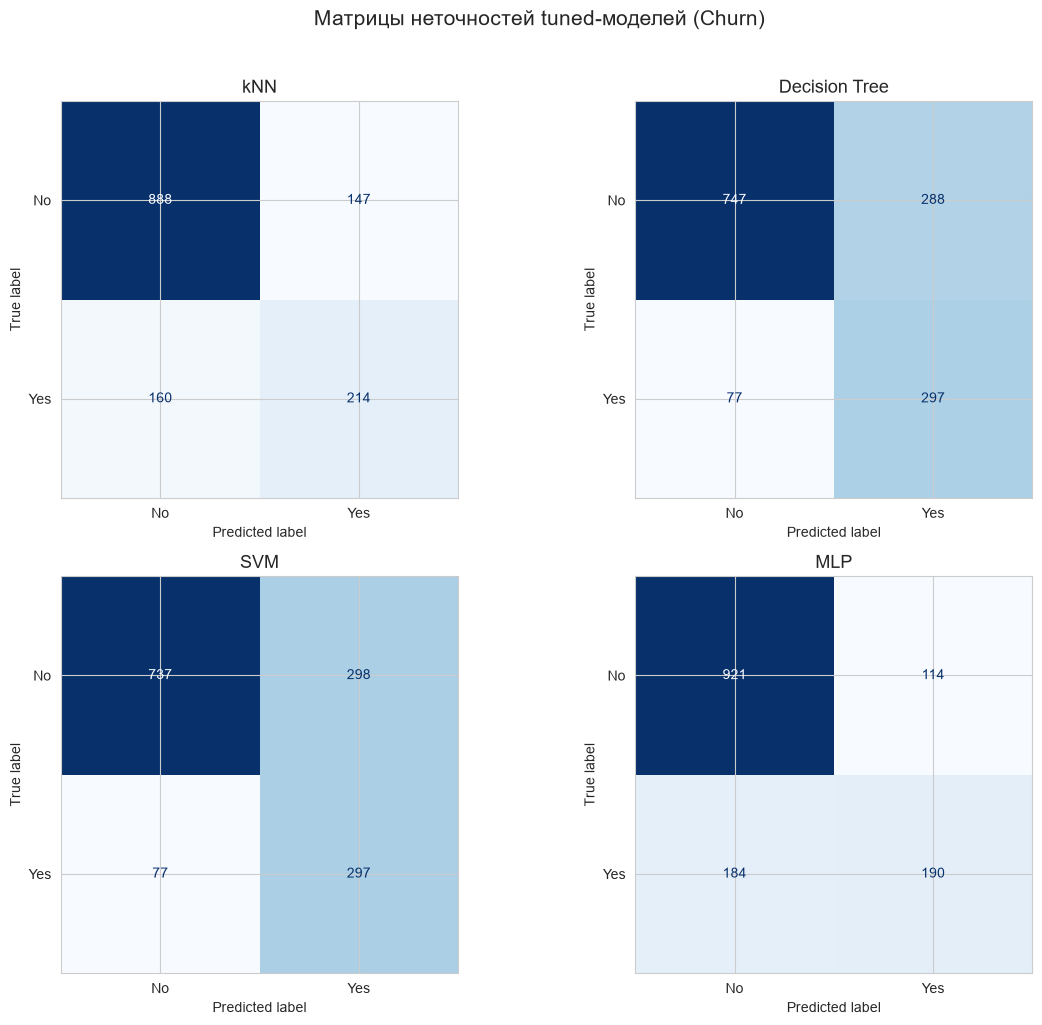

In [35]:
# Confusion Matrix для всех tuned-моделей
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(tuned_predictions_c.items()):
    cm = confusion_matrix(y_test_c, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name}', fontsize=13)

plt.suptitle('Матрицы неточностей tuned-моделей (Churn)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [36]:
# Classification Report
for name, y_pred in tuned_predictions_c.items():
    print("=" * 60)
    print(f"{name}")
    print("=" * 60)
    print(classification_report(y_test_c, y_pred,
                                 target_names=['No churn', 'Churn'],
                                 zero_division=0))
    print()

kNN
              precision    recall  f1-score   support

    No churn       0.85      0.86      0.85      1035
       Churn       0.59      0.57      0.58       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409


Decision Tree
              precision    recall  f1-score   support

    No churn       0.91      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409


SVM
              precision    recall  f1-score   support

    No churn       0.91      0.71      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.73      0.75      1

In [37]:
# Сводная таблица tuned-моделей
summary_c = tuned_df_c.copy()
summary_c = summary_c.sort_values('F1', ascending=False).reset_index(drop=True)

print("=" * 70)
print("СВОДНАЯ ТАБЛИЦА — TELCO CHURN (tuned)")
print("=" * 70)
print(summary_c.to_string(index=False))
print()

best = summary_c.iloc[0]
print(f"Лучшая модель: {best['Model']}")
print(f"F1:            {best['F1']}")
print(f"Recall:        {best['Recall']}")
print(f"Accuracy:      {best['Accuracy']}")

СВОДНАЯ ТАБЛИЦА — TELCO CHURN (tuned)
        Model  Accuracy  Precision  Recall     F1
Decision Tree    0.7410     0.5077  0.7941 0.6194
          SVM    0.7339     0.4992  0.7941 0.6130
          kNN    0.7821     0.5928  0.5722 0.5823
          MLP    0.7885     0.6250  0.5080 0.5605

Лучшая модель: Decision Tree
F1:            0.6194
Recall:        0.7941
Accuracy:      0.741


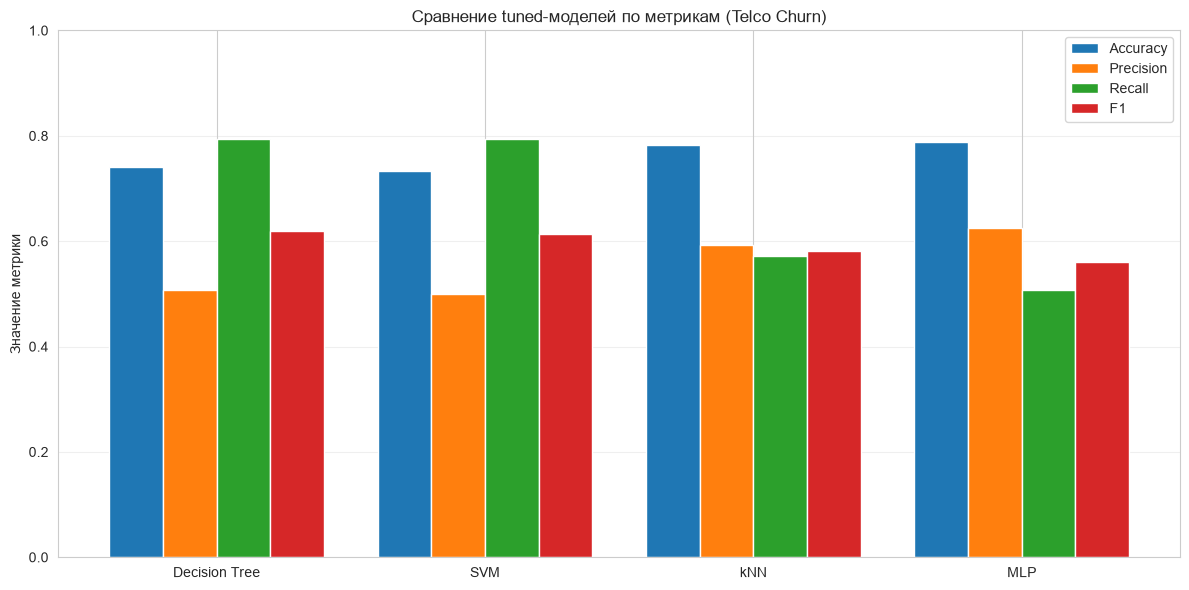

In [38]:
# Визуализация метрик
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(summary_c))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    ax.bar(x + i * width, summary_c[metric], width, label=metric)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(summary_c['Model'])
ax.set_ylabel('Значение метрики')
ax.set_title('Сравнение tuned-моделей по метрикам (Telco Churn)')
ax.legend()
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Оценка качества tuned-моделей (Telco Churn)

### Метрики на тестовой выборке

| Модель | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| **Decision Tree** | 0.741 | 0.508 | **0.794** | **0.6194** |
| SVM | 0.734 | 0.499 | **0.794** | 0.6130 |
| kNN | 0.782 | 0.593 | 0.572 | 0.5823 |
| MLP | **0.789** | **0.625** | 0.508 | 0.5605 |

Метрики считались **по классу Churn (1)** — без усреднения weighted, потому что задача бинарная и нас интересует именно миноритарный класс.

### Ключевое наблюдение: Accuracy vs F1

**Парадокс**, который ярко иллюстрирует проблему дисбаланса классов:

- **MLP лидирует по Accuracy (0.789) и Precision (0.625)** — но по F1 только 0.5605
- **Decision Tree лидирует по F1 (0.6194)** — но по Accuracy лишь третий (0.741)

**Почему так:**
- MLP часто предсказывает «не уйдёт» (precision высокий, recall 0.51) — модель осторожничает, но **пропускает половину уходящих клиентов**
- Decision Tree с `max_depth=7` агрессивнее ловит «Yes» — recall 0.79, но много ложных срабатываний (precision 0.51)

**Вывод:** если бы мы оценивали модели только по accuracy, выбрали бы MLP. Но по F1 — побеждает Decision Tree. А для бизнес-задачи удержания клиентов **FN (пропущенный уходящий) дороже FP**, поэтому **F1 и Recall важнее accuracy**.

### Confusion Matrix

- **FN (False Negative)** — сказали «не уйдёт», а клиент ушёл. **Компания теряет деньги.**
- **FP (False Positive)** — сказали «уйдёт», а клиент остался. Компания **зря потратилась на удержание** (скидка, звонок).

В задаче churn **FN в 5-7 раз дороже FP** — поэтому модели с высоким Recall (DT, SVM) предпочтительнее, даже если Accuracy ниже.

### Итоговый вывод по Churn

**Лучшая модель по F1 — Decision Tree** (F1 = 0.6194, Recall = 0.794):
- Ловит **80% уходящих клиентов** — это ключевой показатель для бизнеса
- Precision 0.51 означает, что примерно половина «тревог» ложные — это приемлемый компромисс
- Плюс дерево **интерпретируемо** — можно показать бизнесу, какие признаки важнее всего

**SVM** показал почти идентичный результат (F1 = 0.6130) — тоже хороший выбор, но менее интерпретируемый.

**kNN и MLP** хоть и дают красивую accuracy, но **пропускают половину уходящих** — для задачи удержания это неприемлемо.

In [39]:
# Итоговая сводка по двум датасетам
print("=" * 80)
print("ИТОГОВАЯ СВОДКА ПО ЛАБОРАТОРНОЙ РАБОТЕ")
print("=" * 80)

# Wine — лучшая модель
best_wine = tuned_df.sort_values('F1 (weighted)', ascending=False).iloc[0]
print("\nДАТАСЕТ №1: Wine Quality (многоклассовая, 6 классов)")
print("-" * 80)
print(f"   Лучшая модель: {best_wine['Model']}")
print(f"   Accuracy:      {best_wine['Accuracy']}")
print(f"   F1 (weighted): {best_wine['F1 (weighted)']}")

# Churn — лучшая модель
best_churn = summary_c.iloc[0]
print("\nДАТАСЕТ №2: Telco Customer Churn (бинарная)")
print("-" * 80)
print(f"   Лучшая модель: {best_churn['Model']}")
print(f"   Accuracy:      {best_churn['Accuracy']}")
print(f"   F1 (Churn):    {best_churn['F1']}")
print(f"   Recall (Churn): {best_churn['Recall']}")

ИТОГОВАЯ СВОДКА ПО ЛАБОРАТОРНОЙ РАБОТЕ

ДАТАСЕТ №1: Wine Quality (многоклассовая, 6 классов)
--------------------------------------------------------------------------------
   Лучшая модель: kNN
   Accuracy:      0.6812
   F1 (weighted): 0.6629

ДАТАСЕТ №2: Telco Customer Churn (бинарная)
--------------------------------------------------------------------------------
   Лучшая модель: Decision Tree
   Accuracy:      0.741
   F1 (Churn):    0.6194
   Recall (Churn): 0.7941


1. Оба датасета требуют разных подходов к предобработке:
   - Wine: все признаки числовые, только StandardScaler
   - Churn: микс числовых и категориальных → ColumnTransformer + Pipeline

2. Метрика оценки зависит от задачи:
   - Wine (6 классов, дисбаланс): F1 weighted
   - Churn (2 класса, сильный дисбаланс): F1 для класса 1 + Recall

3. Accuracy — обманчивая метрика при дисбалансе:
   - На Churn MLP показал лучшую Accuracy (0.789), но проиграл по F1
   - Decision Tree с Accuracy 0.741 выиграл по F1 (0.6194) и Recall (0.794)

4. GridSearchCV + кросс-валидация дали устойчивые оценки:
   - Не всегда тюнинг улучшает test-метрики относительно дефолтов
   - CV показывает средний результат, а конкретный test может дать отклонение

5. Pipeline — правильный подход для смешанных данных:
   - Нет утечки данных
   - Единый интерфейс для GridSearch
   - Меньше кода и меньше ошибок